# 03 — Metro Proximity Association & Route 2020 Event Study

Quantifies residential sales and rental premiums by walking/straight-line distance band (`<500 m`, `500–1000 m`, `1–2 km` relative to `>= 2 km`) and evaluates the 2021 Route 2020 Metro extension using a **Two-Way Fixed Effects** (`Area + Year-Quarter`) Difference-in-Differences & dynamic event study with pre-trend checks.

In [1]:
import json
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dfv.config import PATHS, get_data_mode

mode = get_data_mode()
data_dir = PATHS.processed if mode == "processed" else PATHS.sample
print(f"Active data mode: {mode} | Directory: {data_dir}")

from dfv.analysis.metro_effect import analyze_metro_effect

Active data mode: processed | Directory: /Users/shahinhamza/.gemini/antigravity/scratch/dubai-fair-value/data/processed


In [2]:
metro_json = data_dir / "analysis" / "metro_effect.json"
if metro_json.exists():
    m_res = json.loads(metro_json.read_text(encoding="utf-8"))
else:
    feat = pd.read_parquet(data_dir / "features.parquet")
    rents = pd.read_parquet(data_dir / "rent_contracts.parquet")
    stations = pd.read_parquet(data_dir / "metro_stations.parquet")
    m_res = analyze_metro_effect(feat, rents, stations)

print("Within-area identifiable (sales):", m_res.get("within_area_identifiable"))
print("Sales band counts:", m_res["sales_band_counts"])
print("Sales within-area FE bands:", m_res["sales_distance_bands"])
print("Rents within-area FE bands:", m_res["rents_distance_bands"])
print("Route 2020 DiD summary:", m_res["route_2020_event_study"].get("did_post_effect"))
print("Pre-trend parallel pass:", m_res["route_2020_event_study"].get("pre_trend_parallel_pass"))

Within-area identifiable (sales): False
Sales band counts: {'<500m': 19939, '500-1000m': 76879, '1000-2000m': 105588, '>=2000m': 256739}
Sales within-area FE bands: {}
Rents within-area FE bands: {'band_lt500m': {'term': 'band_lt500m', 'log_coef': 0.10185, 'se_robust': 0.003, 'pct_effect': 10.72, 'ci_low_pct': 10.07, 'ci_high_pct': 11.37, 'p_value': 0.0, 'n_obs': 9982}, 'band_500_1000m': {'term': 'band_500_1000m', 'log_coef': 0.05839, 'se_robust': 0.00323, 'pct_effect': 6.01, 'ci_low_pct': 5.34, 'ci_high_pct': 6.69, 'p_value': 0.0, 'n_obs': 9982}, 'band_1000_2000m': {'term': 'band_1000_2000m', 'log_coef': 0.02373, 'se_robust': 0.0048, 'pct_effect': 2.4, 'ci_low_pct': 1.44, 'ci_high_pct': 3.37, 'p_value': 1e-06, 'n_obs': 9982}}
Route 2020 DiD summary: {'term': 'treated_post', 'log_coef': -0.04833, 'se_robust': 0.00702, 'pct_effect': -4.72, 'ci_low_pct': -6.02, 'ci_high_pct': -3.4, 'p_value': 0.0, 'n_obs': 139094}
Pre-trend parallel pass: True


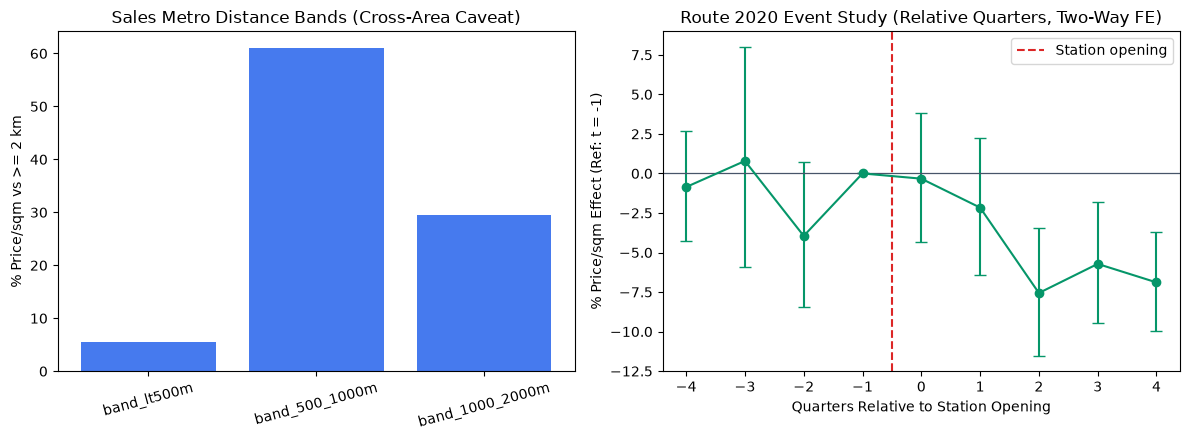

In [3]:
ev = m_res.get("route_2020_event_study", {})
curve = pd.DataFrame(ev.get("event_study_curve", []))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: Rent / Sales distance bands
bands = m_res["sales_distance_bands"] or m_res.get("sales_cross_area_bands", {})
if bands:
    bdf = pd.DataFrame(bands.values())
    axes[0].bar(bdf["term"], bdf["pct_effect"], color="#2563EB", alpha=0.85)
    axes[0].set_title(
        "Sales Metro Distance Bands (%)"
        if m_res.get("sales_distance_bands")
        else "Sales Metro Distance Bands (Cross-Area Caveat)"
    )
    axes[0].set_ylabel("% Price/sqm vs >= 2 km")
    axes[0].tick_params(axis="x", rotation=15)

# Right: Route 2020 dynamic event study
if not curve.empty:
    yerr_lo = curve["pct_effect"] - curve["ci_low_pct"]
    yerr_hi = curve["ci_high_pct"] - curve["pct_effect"]
    axes[1].errorbar(
        curve["rel_quarter"],
        curve["pct_effect"],
        yerr=[yerr_lo, yerr_hi],
        fmt="o-",
        color="#059669",
        capsize=4,
    )
    axes[1].axvline(-0.5, color="#DC2626", linestyle="--", label="Station opening")
    axes[1].axhline(0.0, color="#475569", linewidth=0.9)
    axes[1].set_title("Route 2020 Event Study (Relative Quarters, Two-Way FE)")
    axes[1].set_xlabel("Quarters Relative to Station Opening")
    axes[1].set_ylabel("% Price/sqm Effect (Ref: t = -1)")
    axes[1].legend()

plt.tight_layout()
plt.show()